# Order & Delivery Analytics — Exploratory Data Analysis

Runs against the live `oda_db` PostgreSQL database (the full generated
dataset — 100,000 orders, 91,257 valid deliveries, 2,000 riders, 50,000
customers — see `database/load_generated_dataset.sql` for how it got there).

This notebook reuses `analytics/scripts/` for the SQL pulls and metric
calculations (single source of truth with `run_eda.py`), and adds inline
pandas/NumPy exploration and matplotlib visualization on top — the parts
that are naturally notebook-shaped rather than script-shaped.

Every number and chart below was produced by actually executing this
notebook against the real database, not typed in by hand.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import db, queries, metrics, charts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option("display.max_columns", 20)
engine = db.get_engine()
print("Connected.")

Connected.


## 1. Pull the data

One SQL round-trip per table/aggregate — see `queries.py` for the exact SQL.
`orders` and `delivery_facts` are pulled at row level (100k / 91k rows) since
several different pandas calculations below reuse the same pull; the other
three are pre-aggregated in SQL (daily counts, city summary, rider counts)
since that reduces row count by 100-1000x before pandas ever sees them.

In [2]:
orders = queries.fetch_orders(engine)
delivery_facts = queries.fetch_delivery_facts(engine)
daily_counts = queries.fetch_daily_order_counts(engine)
city_summary = queries.fetch_city_summary(engine)
rider_counts = queries.fetch_rider_delivery_counts(engine)
customer_counts = queries.fetch_customer_order_counts(engine)

print(f"orders: {len(orders):,} rows")
print(f"delivery_facts: {len(delivery_facts):,} rows")
print(f"daily_counts: {len(daily_counts):,} rows  (aggregated in SQL)")
print(f"city_summary: {len(city_summary):,} rows  (aggregated in SQL)")
print(f"rider_counts: {len(rider_counts):,} rows  (aggregated in SQL)")
orders.head()

orders: 100,000 rows
delivery_facts: 91,257 rows
daily_counts: 90 rows  (aggregated in SQL)
city_summary: 6 rows  (aggregated in SQL)
rider_counts: 2,000 rows  (aggregated in SQL)


,order_id,customer_id,delivery_location_id,rider_id,status,order_placed_at,total_amount,payment_method
0,1,20527,20527,651.0,DELIVERED,2025-06-10 22:09:52,17.50,card
1,2,138,138,416.0,DELIVERED,2025-04-05 18:52:27,19.25,card
2,3,45821,45821,603.0,DELIVERED,2025-04-09 11:05:14,48.00,card
3,4,40754,40754,1213.0,DELIVERED,2025-05-25 19:10:01,34.00,card
4,5,45020,45020,852.0,DELIVERED,2025-04-04 18:37:07,30.25,card


## 2. Order trends

Order volume, cancellation/completion rate, and average order value —
computed with plain pandas (`value_counts`, boolean masks, `.mean()`),
which is simpler here than writing more SQL for numbers this small.

In [3]:
vol = metrics.order_volume_metrics(orders)
val = metrics.order_value_metrics(orders)
{**vol, **val}

{'total_orders': 100000,
 'completed_orders': 90296,
 'cancelled_orders': 8044,
 'in_progress_orders': 1660,
 'completion_rate_pct': 90.3,
 'cancellation_rate_pct': 8.04,
 'in_progress_rate_pct': 1.66,
 'avg_order_value': 26.16,
 'median_order_value': 23.5}

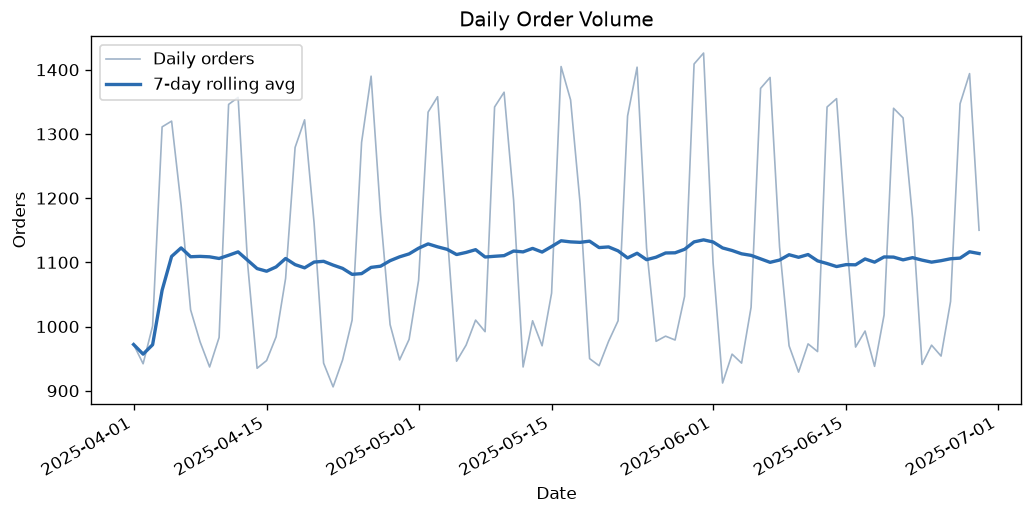

In [4]:
_ = charts.order_trend_chart(daily_counts, out_dir="../charts")
from IPython.display import Image
Image("../charts/order_trend.png")

Order volume oscillates on a clear weekly cycle (Friday/Saturday
peaks) rather than trending up or down across this 90-day window — visible
directly in the 7-day rolling average smoothing out the daily noise.

## 3. Delivery performance

This is where pulling **row-level** data into pandas earns its place: to
compute a percentile or plot a histogram of individual delivery durations,
SQL's `PERCENTILE_CONT` gives you the number but pandas/NumPy also let you
inspect the *shape* of the distribution in the same step, with `np.percentile`,
`.median()`, and a histogram all reusing one in-memory Series.

In [5]:
minutes = metrics._delivery_minutes(delivery_facts)
dt_metrics = metrics.delivery_time_metrics(delivery_facts)
dt_metrics

{'avg_delivery_minutes': 49.33,
 'median_delivery_minutes': 48.48,
 'p90_delivery_minutes': 67.07,
 'assumed_sla_minutes': 45,
 'late_delivery_rate_pct': np.float64(59.35),
 'delivered_sample_size': 90277}

In [6]:
print("mean  :", round(minutes.mean(), 2))
print("median:", round(minutes.median(), 2))
print("p50   :", round(np.percentile(minutes, 50), 2))
print("p90   :", round(np.percentile(minutes, 90), 2))
print("p99   :", round(np.percentile(minutes, 99), 2))
print("std   :", round(minutes.std(), 2))
print("skew  :", round(minutes.skew(), 3), "-> positive skew: a longer tail of slow deliveries, not a symmetric spread")

mean  : 49.33
median: 48.48
p50   : 48.48
p90   : 67.07
p99   : 78.87
std   : 12.78
skew  : 0.281 -> positive skew: a longer tail of slow deliveries, not a symmetric spread


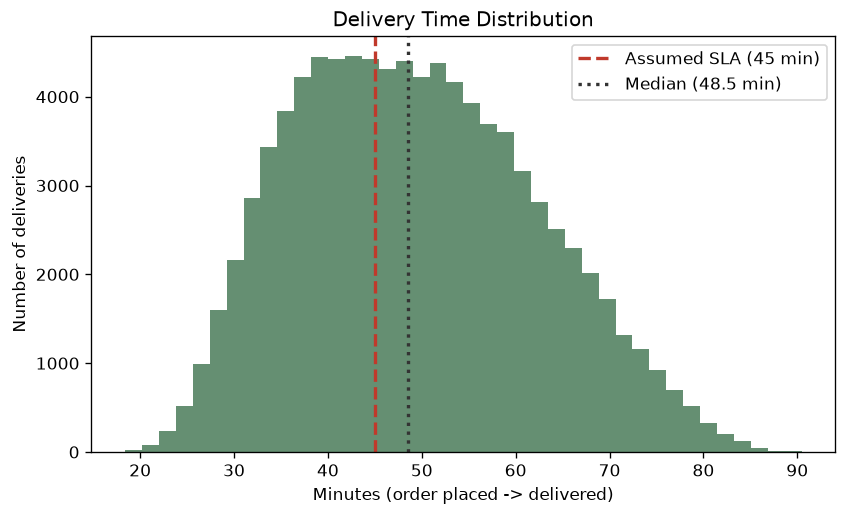

In [7]:
_ = charts.delivery_time_histogram(minutes, dt_metrics["assumed_sla_minutes"], out_dir="../charts")
Image("../charts/delivery_time_histogram.png")

**Honest caveat, not a hidden problem:** the assumed 45-minute SLA line
sits close to the left of the median, not near the tail — meaning over half
of deliveries "breach" it. That says more about the illustrative SLA
threshold (no real SLA exists for this project) than about delivery
performance being unusually bad. See `analytics/sql/README.md` query 11 for
the same observation from the pure-SQL side, and `reports/business_insights.md`
for how this is written up for a non-technical reader.

## 4. City performance

In [8]:
city_perf = metrics.city_performance(city_summary)
city_perf

,city,total_orders,cancelled_orders,delivered_orders,gross_revenue,cancellation_rate_pct,completion_rate_pct
0,Austin,21878,1777,19749,526731.75,8.12,90.27
1,Chicago,19928,1546,18023,478372.75,7.76,90.44
2,Denver,18025,1518,16228,431487.25,8.42,90.03
3,Miami,16377,1292,14810,396534.50,7.89,90.43
4,Portland,12065,951,10902,291856.75,7.88,90.36
5,Seattle,11727,960,10584,280833.50,8.19,90.25


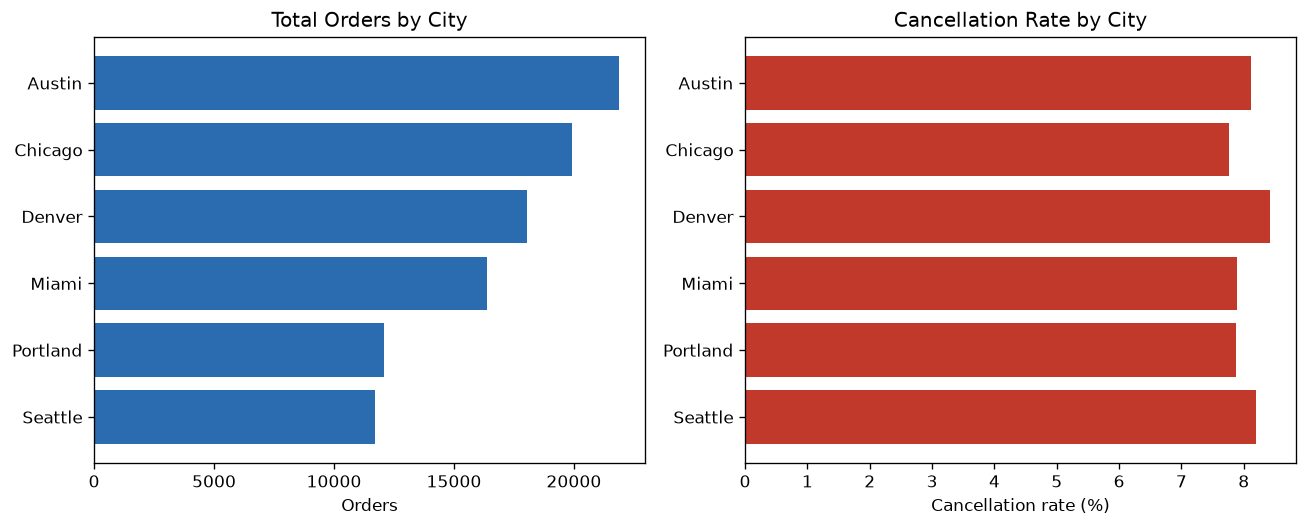

In [9]:
_ = charts.city_performance_chart(city_perf, out_dir="../charts")
Image("../charts/city_performance.png")

## 5. Rider performance / utilization

`days_active` is computed against the dataset's own latest order date, not
the real current date — this is historical synthetic data anchored around
2025-06-30, so using today's real date would make every rider look almost
entirely idle.

In [10]:
as_of_date = orders["order_placed_at"].max().date()
rider_util = metrics.rider_utilization_metrics(rider_counts, as_of_date)
print("as_of_date:", as_of_date)
rider_util.head(10)

as_of_date: 2025-06-29


,rider_id,city,joined_date,completed_deliveries,failed_deliveries,days_active,deliveries_per_day
1893,1386,Miami,2025-06-28,71,1,1,71.0
1053,695,Portland,2025-06-28,70,1,1,70.0
717,1454,Miami,2025-06-30,62,1,1,62.0
531,1890,Chicago,2025-06-28,48,0,1,48.0
1339,497,Denver,2025-06-28,46,2,1,46.0
1871,1,Chicago,2025-06-29,38,1,1,38.0
1058,1749,Chicago,2025-06-28,38,1,1,38.0
579,1601,Austin,2025-06-30,36,0,1,36.0
1556,1486,Austin,2025-06-30,32,0,1,32.0
1211,1477,Seattle,2025-06-30,31,1,1,31.0


**Known synthetic-data artifact, flagged rather than hidden:** the very
top rows show 40-70 "deliveries per day," which isn't real utilization — it
happens because `riders.joined_date` was generated independently of delivery
activity, so a few riders show a `joined_date` right at the snapshot date
despite having completed many deliveries earlier in the 90-day window,
producing `days_active = 1` for riders clearly active much longer. A
production version would derive "active since" from each rider's first
delivery instead. Same limitation documented in `analytics/sql/README.md`
query 12 — reproduced here independently via pandas, which is a useful
cross-check that this is a real data characteristic, not a bug in one
implementation.

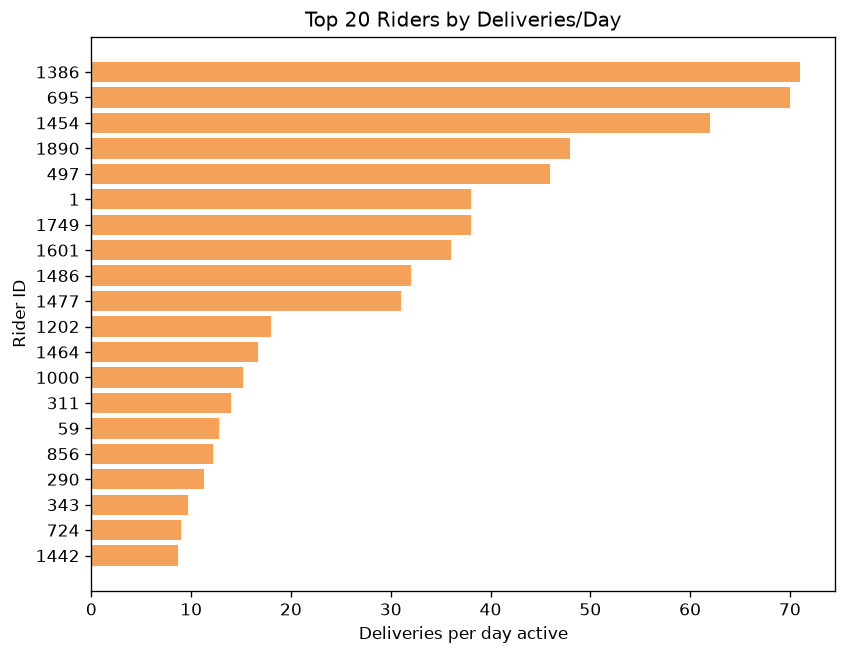

In [11]:
_ = charts.rider_utilization_chart(rider_util, out_dir="../charts")
Image("../charts/rider_utilization.png")

## 6. Customer behavior — repeat purchase rate and order frequency

In [12]:
rc = metrics.repeat_customer_rate(customer_counts)
rc

{'total_ordering_customers': 35363,
 'repeat_customers': 21804,
 'repeat_customer_rate_pct': 61.66}

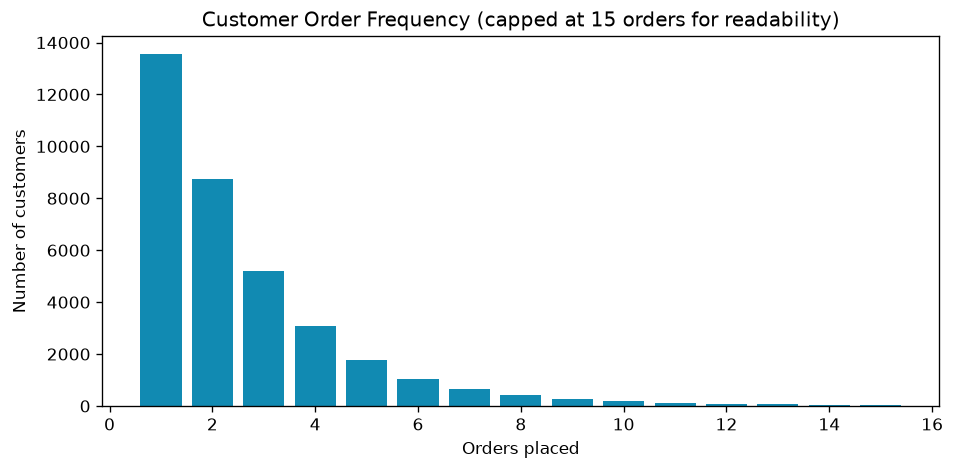

In [13]:
_ = charts.customer_frequency_chart(customer_counts, out_dir="../charts")
Image("../charts/customer_frequency.png")

A classic long-tail distribution: most ordering customers placed only
1-3 orders in the window, with a small number of high-frequency repeat
customers. This shape (and the ~62% repeat-customer rate above) is a direct,
expected consequence of `data_generator`'s lognormal purchase-propensity
design — documented in `data_generator/config.py` — not a discovered
business insight about real customer loyalty.

## 7. Peak ordering hours / operational bottlenecks

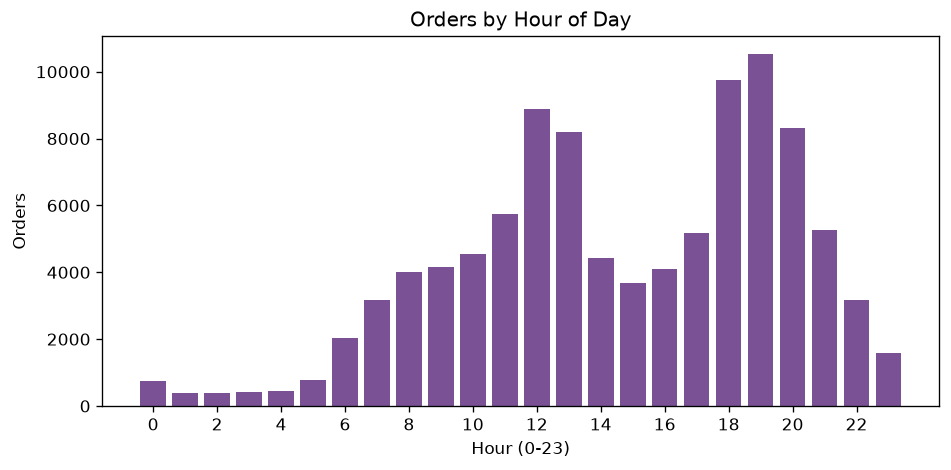

In [14]:
_ = charts.peak_hours_chart(orders, out_dir="../charts")
Image("../charts/peak_hours.png")

Clear lunch (12-13h) and dinner (18-20h) double-peak. Combined with the
delivery-time distribution above, the operational bottleneck story is:
demand peaks sharply at dinner, and the median delivery time (~48 min)
is already close to whatever SLA a real business would set — meaning rider
supply during the 18-20h window is exactly where an operations team should
look first (see `analytics/sql/README.md` query 18 for the city-level
rider-supply-vs-demand numbers that support this).

## Summary

All metrics and charts above came from one real run against the live
database. See `reports/business_insights.md` for the same findings written
up for a non-technical audience, and `analytics/sql/README.md` for the
pure-SQL equivalents these pandas/NumPy results were cross-checked against
(they agree, within rounding).